---
title: "Modul 4 Struktur Data: Stack dan Queue"
subtitle: "Stack dan Queue"
image: https://raw.githubusercontent.com/aslab-math-ui/asset/main/struktur_data/static/stack.png
description: "Offline di Departemen Matematika"
date: 10/05/2026
page-navigation: true
format: html
fig-width: 6
fig-height: 2.5
---

Kembali ke [Struktur Data](./strukdat2026.qmd)

Di praktikum kali ini tentang *stack*, kita akan membahas implementasi *stack* (baik dengan *array* maupun dengan *linked list*) serta contoh penggunaannya.

In [2]:
import numpy as np
import graphviz as gv

# Implementasi dan contoh penggunaan *stack*

## Implementasi *stack* dengan *array*

In [3]:
class ArrayStack:
    def __init__(self, dtype, max):
        self.dtype = dtype
        self.max = max
        self.array = np.empty(max, dtype=dtype)
        self.top = -1
    
    def get_size(self):
        return self.top + 1
    
    def get_capacity(self):
        return self.max
    
    def get_dtype(self):
        return self.dtype

    def is_empty(self):
        if self.get_size() > 0:
            return False
        else:
            return True
    
    def is_full(self):
        if self.get_size() >= self.get_capacity():
            # if top+1 >= max
            # atau sama saja, if top >= max-1
            return True
        else:
            return False

    def push(self, newdata):
        if self.is_full():
            print("Error push: stack sudah penuh.")
        else:
            self.top += 1
            self.array[self.top] = newdata
    
    def peek(self):
        if self.is_empty():
            print("Error peek: stack sedang kosong.")
            return None
        else:
            return self.array[self.top]
    
    def pop(self):
        if self.is_empty():
            print("Error pop: stack sudah kosong sebelumnya.")
            return None
        else:
            output = self.array[self.top]
            self.top -= 1
            return output

    def print_stack(self):
        i = self.top
        while i >= 0:
            print(self.array[i])
            i -= 1

    # print array
    def print_storage(self):
        print(self.array)
    
    def get_digraph_stack(self):
        new_digraph = gv.Digraph()
        # gambar akan terdiri dari satu tabel saja, satu kolom,
        # dan tiap baris adalah tiap elemen di stack

        tabel_besar = "<"
        # pembuka tabel
        tabel_besar += "<TABLE BORDER=\"0\" CELLBORDER=\"1\" CELLSPACING=\"0\">"
        # menambahkan tiap elemen sebagai baris tersendiri
        i = self.top
        if i < 0:
            tabel_besar += "<TR><TD>"
            tabel_besar += "(Stack sedang kosong; tidak ada data sama sekali.)"
            tabel_besar += "</TD></TR>"
        while i >= 0:
            tabel_besar += "<TR><TD>"
            tabel_besar += str(self.array[i])
            tabel_besar += "</TD></TR>"
            i -= 1
        # penutup tabel
        tabel_besar += "</TABLE>"
        tabel_besar += ">"
        new_digraph.node("ArrayStack", shape="none", label=tabel_besar)
        return new_digraph

    def get_digraph_storage(self):
        # menggambar array
        new_digraph = gv.Digraph()

        # pembuka tabel
        tabel_besar = "<"
        tabel_besar += "<TABLE BORDER=\"0\" CELLBORDER=\"1\" CELLSPACING=\"0\">"
        # tabel hanya terdiri dari satu baris
        tabel_besar += "<TR>"
        # satu elemen per kolom
        for i in range(self.get_capacity()):
            tabel_besar += "<TD>"
            tabel_besar += str(self.array[i])
            tabel_besar += "</TD>"
        # penutup baris
        tabel_besar += "</TR>"
        # penutup tabel
        tabel_besar += "</TABLE>"
        tabel_besar += ">"
        new_digraph.node("array", shape="none", label=tabel_besar)
        return new_digraph

In [31]:
arraystack = ArrayStack(int, 5)
arraystack.push(5)
arraystack.push(80)
arraystack.push(100)

In [32]:
arraystack.print_stack()

100
80
5


In [33]:
print(arraystack.get_capacity())

5


In [34]:
arraystack.print_storage()

[                  5                  80                 100
 4622241330054037504 4625478292286210048]


In [35]:
print(arraystack.peek())

100


In [36]:
arraystack.print_stack()

100
80
5


In [37]:
nilai = arraystack.pop()
print(nilai)

100


In [38]:
arraystack.print_stack()

80
5


In [39]:
arraystack.print_storage()

[                  5                  80                 100
 4622241330054037504 4625478292286210048]


In [40]:
arraystack.push(-10)
arraystack.push(57)

In [41]:
arraystack.print_stack()

57
-10
80
5


In [42]:
arraystack.print_storage()

[                  5                  80                 -10
                  57 4625478292286210048]


In [43]:
graf1 = arraystack.get_digraph_stack()

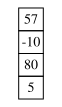

In [44]:
display(graf1)

In [45]:
graf2 = arraystack.get_digraph_storage()

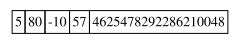

In [46]:
display(graf2)

In [47]:
arraystack.push(90)

In [48]:
arraystack.push(46)

Error push: stack sudah penuh.


In [49]:
arraystack.print_storage()

[  5  80 -10  57  90]


In [50]:
print(arraystack.pop())
print(arraystack.pop())
print(arraystack.pop())
print(arraystack.pop())
print(arraystack.pop())

90
57
-10
80
5


In [51]:
print(arraystack.pop())

Error pop: stack sudah kosong sebelumnya.
None


In [52]:
print(arraystack.get_size())

0


In [53]:
arraystack.print_stack()

In [54]:
arraystack.print_storage()

[  5  80 -10  57  90]


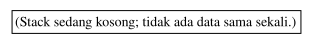

In [55]:
display(arraystack.get_digraph_stack())

## Implementasi *stack* dengan *singly-inked list*

In [4]:
class SLNode:
    def __init__(self, data, next=None):
        self.data = data
        self.next = next

In [1]:
class SLStack:
    def __init__(self):
        # "head" ganti nama jadi top
        self.top = None
    
    def is_empty(self):
        if self.top == None:
            return True
        else:
            return False
    
    def push(self, newdata):
        newnode = SLNode(newdata)
        newnode.next = self.top
        self.top = newnode
    
    def peek(self):
        if self.is_empty():
            print("Error peek: stack sedang kosong.")
        else:
            return self.top.data
    
    def pop(self):
        if self.is_empty():
            print("Error pop: stack sudah kosong sebelumnya.")
        else:
            output = self.top.data
            temp = self.top
            self.top = self.top.next
            del temp
            return output
    
    def get_size(self):
        temp = self.top
        size = 0
        while temp != None:
            size += 1
            temp = temp.next
        return size

    def print_stack(self):
        temp = self.top
        while temp != None:
            print(temp.data)
            temp = temp.next
    
    # print linked list
    def print_storage(self):
        print("top -> ", end="")
        temp = self.top
        while temp != None:
            print(temp.data, end=" -> ")
            temp = temp.next
        print("None")
    
    def get_digraph_stack(self):
        new_digraph = gv.Digraph()
        # gambar akan terdiri dari satu tabel saja, satu kolom,
        # dan tiap baris adalah tiap elemen di stack
        tabel_besar = ""
        tabel_besar += "<"
        tabel_besar += "<TABLE BORDER=\"0\" CELLBORDER=\"1\" CELLSPACING=\"0\">"
        temp = self.top
        if temp == None:
            tabel_besar += "<TR><TD>"
            tabel_besar += "(Stack sedang kosong; tidak ada data sama sekali.)"
            tabel_besar += "</TD></TR>"
        while temp != None:
            tabel_besar += "<TR><TD>"
            tabel_besar += str(temp.data)
            tabel_besar += "</TD></TR>"
            temp = temp.next
        # penutup tabel
        tabel_besar += "</TABLE>"
        tabel_besar += ">"
        new_digraph.node("SLStack", shape="none", label=tabel_besar)
        return new_digraph

    # copas dari modul linked list, tapi head ganti jadi top
    def get_digraph_storage(self):
        # Buat digraph baru yang sifatnya dari kiri ke kanan
        new_digraph = gv.Digraph(graph_attr={"rankdir": "LR"})
        
        # Pointer untuk menunjuk ke tiap node, mulai dari node pertama
        # (akan dilakukan traversal)
        current = self.top

        # Untuk menghitung node ke-sekian untuk nama node di Graphviz,
        # sehingga top menunjuk ke node0, lalu node0 menunjuk ke node1, dst
        counter = 0

        # Memperoleh alamat yang sedang disimpan di top
        # - asumsi awal: tidak ada alamat (None)
        next_id = None
        next_name = "node0" # ini nanti untuk nama node berikutnya di Graphviz
        # - kalau ternyata ada alamat...
        if current != None:
            # maka simpan alamat tersebut
            next_id = hex(id(current))
            # kita buat lebih spesifik untuk node berikutnya, tunjuk ke port id
            next_name = "node0:id"
        
        # Label (tabel) untuk pointer top
        # - pembuka tabel
        str_label = "<"
        str_label += "<TABLE BORDER=\"0\" CELLBORDER=\"1\" CELLSPACING=\"0\">"
        # - baris top
        str_label += "<TR><TD>top</TD></TR>"
        # - baris alamat (sekalian membuat port namanya "contents")
        str_label += "<TR><TD PORT=\"contents\">" + str(next_id) + "</TD></TR>"
        # - penutup tabel
        str_label += "</TABLE>"
        str_label += ">"

        # Membuat node top, membuat edge dari top ke node berikutnya
        new_digraph.node("top", shape="none", label=str_label)
        new_digraph.edge("top:contents", next_name)
        # dari port "contents" ke node berikutnya, yang namanya next_name
        
        # Selama node yang ditunjuk bukan None, buatlah node nya di Graphviz,
        # lalu lanjut ke node selanjutnya (ini traversal)
        while current != None:
            # Alamat yang tersimpan pada current.next
            # - asumsi awal: tidak ada alamat; current adalah node terakhir
            next_id = None
            # - kalau ternyata ada alamat...
            if current.next != None:
                # maka simpan alamat tersebut
                next_id = hex(id(current.next))
            
            # Persiapan label (tabel) untuk node
            # - pembuka tabel
            str_label = "<"
            str_label += "<TABLE BORDER=\"0\" CELLBORDER=\"1\" CELLSPACING=\"0\">"
            # - baris tulisan "data", "next"
            str_label += "<TR><TD>data</TD><TD>next</TD></TR>"
            # - baris untuk isi data dan isi next
            str_label += "<TR>"
            str_label += "<TD>" + str(current.data) + "</TD>"
            str_label += "<TD PORT=\"next\">" + str(next_id) + "</TD>"
            str_label += "</TR>"
            # - baris tulisan "alamat node", merentang dua kolom
            str_label += "<TR><TD COLSPAN=\"2\">alamat node</TD></TR>"
            # - baris untuk isi alamat node, merentang dua kolom
            str_label += "<TR>"
            str_label += "<TD PORT=\"id\" COLSPAN=\"2\">"
            str_label += str(hex(id(current)))
            str_label += "</TD>"
            str_label += "</TR>"
            # - penutup tabel
            str_label += "</TABLE>"
            str_label += ">"

            # Membuat node baru di Graphviz dengan label (tabel) tersebut
            new_digraph.node("node" + str(counter), shape="none", label = str_label)

            # Menentukan nama dua port yang bakal disambung dengan edge,
            # yaitu (node saat ini):next disambung ke node(berikutnya):id
            # yaitu bagian "next" disambung ke bagian alamat di node berikutnya
            nama_node_next = "node" + str(counter) + ":next"
            if current.next != None:
                nama_alamat_node_berikutnya = "node" + str(counter+1) + ":id"
            # atau ke node(berikutnya) saja tanpa id kalau itu ternyata None,
            # karena None tidak akan memiliki port id
            else:
                nama_alamat_node_berikutnya = "node" + str(counter+1)
            
            # Menyambung keduanya
            new_digraph.edge(nama_node_next, nama_alamat_node_berikutnya)
            
            # Lanjut ke node selanjutnya
            current = current.next
            counter += 1
        # Kalau sudah keluar loop, artinya current menunjuk ke None
        # Berarti tinggal membuat "node" terakhir berisi tulisan None
        # (karena sambungannya sudah dibuat di dalam loop, tinggal node nya)
        new_digraph.node("node" + str(counter), shape="none", label="None")

        # Digraph sudah jadi
        return new_digraph

In [103]:
slstack = SLStack()
slstack.print_storage()

top -> None


In [104]:
slstack.push("abc")
slstack.push("fg")
slstack.push("ijk")
slstack.push("pqrs")
slstack.push("xyz")

In [105]:
slstack.print_stack()

xyz
pqrs
ijk
fg
abc


In [106]:
slstack.print_storage()

top -> xyz -> pqrs -> ijk -> fg -> abc -> None


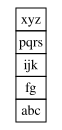

In [107]:
display(slstack.get_digraph_stack())

In [108]:
print(slstack.pop())
print(slstack.pop())
print(slstack.pop())

xyz
pqrs
ijk


In [109]:
slstack.print_stack()

fg
abc


In [110]:
slstack.print_storage()

top -> fg -> abc -> None


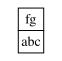

In [111]:
display(slstack.get_digraph_stack())

## Contoh sederhana: *reverse* suatu *list*/*array*

# *Queue* Linear

## Implementasi *Queue* dengan *Array*

## Implementasi *Queue* dengan *Linked List*

In [ ]:
# definisikan node dari suatu linked list
class SLNode:
    def __init__(self, data, next=None):
        self.data = data
        self.next = next

In [ ]:
class SLLinQueue:
    # definisikan queue dengan linked list
    def __init__(self):
        # head=front, tail=rear
        self.front = None
        self.rear = None

    # cek apakah queue kosong
    def is_empty(self):
        if self.front == None:
            return True
        else:
            return False

    # mengetahui banyaknya elemen pada queue
    def get_size(self):
        size = 0
        temp = self.front
        while (temp != None):
            size += 1
            temp = temp.next
        return size

    # insert di akhir linked list
    def enqueue(self, newdata):
        newnode = SLNode(newdata)

        # kasus saat queue kosong
        if self.is_empty():
            self.front = newnode
            self.rear = newnode

        # kasus saat queue tidak kosong
        else:
            self.rear.next = newnode
            self.rear = newnode

    # mengintip isi dari queue di awal
    def peek(self):

        # kasus saat queue kosong
        if self.is_empty():
            print("Error peek: queue sedang kosong")
            return None

        # kasus saat queue tidak kosong
        else:
            return self.front.data

    # hapus di awal linked list
    def dequeue(self):

        # kasus saat queue kosong
        if self.is_empty():
            print("Error dequeue: queue sudah kosong")
            return None

        # kasus saat queue tidak kosong
        else:
            output = self.front.data
            temp = self.front
            self.front = self.front.next
            del temp # hapus node yang tidak penting
            return output

    # cetak queue yang dimiliki
    def print_queue(self):
        print("front : ", end="")

        # kasus saat queue kosong
        if self.is_empty():
            print("(tidak ada data) : rear")

        # kasus queue tidak kosong
        else:
            temp = self.front
            while temp != None:
                if temp.next != None:
                    print(temp.data, end = " | ")
                else:
                    print(temp.data, end="")
                temp = temp.next
            print(" : rear")

    # cetak queue yang dimiliki *versi lain
    def print_storage(self):
        print("front -> ", end="")

        # kasus saat queue kosong
        if self.is_empty():
            print("None <- rear")

        # kasus queue tidak kosong
        else:
            temp = self.front
            while temp != None:
                if temp.next != None:
                    print(temp.data, end = " -> ")
                else:
                    print(temp.data, end = " <- ")
                temp = temp.next
            print("rear")

Contoh Penggunaan *Queue* dengan *Linked List*

In [ ]:
queueLinLinked = SLLinQueue()

In [ ]:
queueLinLinked.print_queue()

front : (tidak ada data) : rear


In [ ]:
queueLinLinked.enqueue(1)
queueLinLinked.print_queue()

front : 1 : rear


In [ ]:
for i in range(3):
    queueLinLinked.enqueue(i*5)

queueLinLinked.print_queue()

front : 1 | 0 | 5 | 10 : rear


In [ ]:
queueLinLinked.print_storage()

front -> 1 -> 0 -> 5 -> 10 <- rear


In [ ]:
queueLinLinked.get_size()

4

In [ ]:
queueLinLinked.dequeue()

queueLinLinked.print_storage()

front -> 0 -> 5 -> 10 <- rear


In [ ]:
for i in range(queueLinLinked.get_size()):
    queueLinLinked.dequeue()

queueLinLinked.print_storage()

front -> None <- rear


In [ ]:
queueLinLinked.dequeue()

Error dequeue: queue sudah kosong


In [ ]:
def reverse_array_arraystack(array_old):
    array = array_old.copy()

    # memeriksa tipe data dari elemen pertama
    tipe_data = type(array[0])
    # khusus array, bisa juga menggunakan array.dtype

    arraystack = ArrayStack(tipe_data, len(array))
    for i in range(len(array)):
        arraystack.push(array[i])
    for i in range(len(array)):
        array[i] = arraystack.pop()
    return array

In [ ]:
list1 = ["m", "a", "t", "e", "k"]
list2 = reverse_array_arraystack(list1)
print(list2)

['k', 'e', 't', 'a', 'm']


In [ ]:
def reverse_array_slstack(array_old):
    array = array_old.copy()
    slstack = SLStack()
    for i in range(len(array)):
        slstack.push(array[i])
    for i in range(len(array)):
        array[i] = slstack.pop()
    return array

In [ ]:
array1 = np.array(["m", "a", "t", "e", "k"])
array2 = reverse_array_slstack(array1)
print(array2)

['k' 'e' 't' 'a' 'm']


In [ ]:
class ArrayLinQueue:
    # definisikan queue dengan array
    def __init__(self, dtype, array_max):
        self.dtype = dtype
        self.array_max = array_max
        self.array = np.empty(array_max, dtype = dtype)
        self.front = -1
        self.rear = -1

    # mengetahui banyaknya elemen pada queue
    def get_size(self):
        # kasus saat queue kosong
        if self.is_empty():
            return 0

        # kasus queue tidak kosong
        else:
            size = (self.rear - self.front) + 1
            return size

    # mengetahui kapasitas sesungguhnya dari queue
    def get_capacity_array(self):
        return self.array_max

    # mengetahui kapasitas yang tersisa dari queue
    def get_capacity_queue(self):
        # kasus saat queue belum digunakan
        if self.front == -1:
            capacity_queue = self.array_max

        # kasus saat queue sudah digunakan
        else:
            capacity_queue = self.array_max - self.rear - 1 #perlu debugging ketika sudah full
        return capacity_queue

    # cek apakah queue kosong
    def is_empty(self):
        if self.front == -1:
            return True
        else:
            return False

    # cek apakah queue sudah penuh
    def is_full(self):
        if self.rear == self.array_max - 1:
            return True
        else:
            return False

    # metode enqueue
    def enqueue(self, newdata):
        # Kondisi ketika array penuh
        if self.is_full():
            print("Error enqueue: queue sudah memenuhi batas maksimum")

        # Kasus ketika queue masih kosong di awal
        elif self.front == -1:
            self.front += 1
            self.rear += 1
            self.array[self.rear] = newdata

        # kasus ketika queue sudah tidak kosong di awal
        else:
            self.rear += 1
            self.array[self.rear] = newdata

    # mengintip isi dari queue di awal
    def peek(self):
        if self.is_empty():
            print("Error peek: queue sedang kosong")
        else:
            return self.array[self.front]

    # metode dequeue
    def dequeue(self):
        # kasus saat queue kosong
        if self.is_empty():
            print("Error dequeue: queue sudah kosong sebelumnya")
            return None

        # kasus hanya satu elemen pada queue
        elif (self.get_size() == 1):
            # Jika di queue hanya ada satu elemen, dan ingin di-dequeue,
            # maka queue akan kosong setelah itu
            # kita reset queue kita jadi kosong
            output = self.array[self.front]
            self.front = -1
            self.rear = -1
            return output

        # kasus umum pada queue
        else:
            output = self.array[self.front]
            self.front += 1
            return output

    # mencetak semua elemen pada queue
    def print_storage(self):
        print(self.array)

    def display(self):
        return self.array

    # mencetak queue *versi lain
    def print_queue(self):
        print("front : ", end="")
        if self.is_empty():
            print("(tidak ada data) : rear")
        else:
            for i in range(self.front, self.rear): # i = front, ..., rear-1
                print(self.array[i], end=" | ")
            print(self.array[self.rear], end="") # untuk i = rear
            print(" : rear")

Contoh penggunaan *Queue* dengan *Array*

In [ ]:
queueLinArray = ArrayLinQueue(dtype = int, array_max=10)

In [ ]:
queueLinArray.get_capacity_array()

10

In [ ]:
queueLinArray.print_queue()

front : (tidak ada data) : rear


In [ ]:
queueLinArray.enqueue(1)
queueLinArray.print_queue()

front : 1 : rear


In [ ]:
for i in range(3):
    queueLinArray.enqueue(i*5)

queueLinArray.print_queue()

front : 1 | 0 | 5 | 10 : rear


In [ ]:
queueLinArray.print_storage()

[                  1                   0                   5
                  10 7599578574504329216 3761739758475294518
 3617566120052078381 3256163233075901495 4050536193999398197
 8026364514949935924]


In [ ]:
print(f"Banyaknya elemen pada queue: {queueLinArray.get_size()}")
print(f"Kapasitas yang tersedia: {queueLinArray.get_capacity_queue()}")

Banyaknya elemen pada queue: 4
Kapasitas yang tersedia: 6


In [ ]:
queueLinArray.dequeue()

1

In [ ]:
print(f"Banyaknya elemen pada queue: {queueLinArray.get_size()}")
print(f"Kapasitas yang tersedia: {queueLinArray.get_capacity_queue()}")
queueLinArray.print_queue()

Banyaknya elemen pada queue: 3
Kapasitas yang tersedia: 6
front : 0 | 5 | 10 : rear


In [ ]:
for i in range(queueLinArray.get_size()):
    queueLinArray.dequeue()

In [ ]:
queueLinArray.dequeue()

Error dequeue: queue sudah kosong sebelumnya


# *Circular Queue*

Masalah utama dalam *linear queue* dengan array adalah saat melakukan *enqueue* dan *dequeue*, kedua *pointer* hanya akan berjalan ke kanan. Artinya ketika *pointer* depan telah sampai ke indeks terakhir di array, program akan menganggap *queue* telah penuh, meskipun elemen di indeks awal array sudah di *dequeue*.

Untuk mengatasi hal ini, kita dapat membuat *pointer* depan kembali ke awal jika *pointer* tersebut telah melewati indeks terakhir dari array dan lanjut mengisi *queue* mulai dari indeks pertama hingga *pointer* depan bertemu dengan *pointer* belakang. Implementasi *queue* seperti ini disebut *circular queue*.

## Implementasi *Circular Queue* dengan *Array*

In [ ]:
# mulai dari sini, untuk memudahkan circular queue
# akan disebut sebagai queue saja

class ArrayCircQueue:
    # definisikan queue dengan array
    def __init__(self, dtype, max):
        self.dtype = dtype
        self.max = max
        self.array = np.empty(max, dtype=dtype)
        self.front = -1
        self.rear = -1

    # cek apakah queue kosong
    def is_empty(self):
        if self.front == -1:
            return True
        else:
            return False

    # cek apakah queue penuh
    def is_full(self):
        # kasus saat rear modulo max sama dengan front
        # dapat dibayangkan sebagai rear tepat di belakang front
        # pada diagram array lingkaran
        if self.front == (self.rear + 1) % self.max:
            return True
        else:
            return False

    # mengetahui banyaknya elemen pada queue
    def get_size(self):
        # kasus saat kosong
        if self.is_empty():
            size = 0

        # kasus front di belakang rear
        elif self.front <= self.rear:
            size = (self.rear - self.front) + 1

        # kasus rear di belakang front
        else:
            size = self.max - (self.front - self.rear - 1)

        return size

    # mengetahui kapasitas queue
    def get_capacity(self):
        return self.max

    # metode enqueue
    def enqueue(self, newdata):

        # kasus queue penuh
        if self.is_full():
            print("Error enqueue: queue sudah penuh sebelumnya")

        # kasus queue kosong
        elif self.front == -1:
            self.front += 1
            self.rear += 1
            self.array[self.rear] = newdata

        # kasus ketika queue sudah tidak kosong
        else:
            self.rear = (self.rear + 1) % self.max # hanya berbeda di sini
            self.array[self.rear] = newdata

    # mengintip isi dari queue di awal
    def peek(self):
        if self.is_empty():
            print("Error peek: queue sedang kosong")
        else:
            return self.array[self.front]

    # mnetode dequeue
    def dequeue(self):

        # kasus ketika queue kosong
        if self.is_empty():
            print("Error dequeue: queue sudah kosong sebelumnya")
            return None

        # kasus hanya satu elemen pada queue
        elif (self.get_size() == 1):
            # Jika di queue hanya ada satu elemen, dan ingin di-dequeue,
            # maka queue akan kosong setelah itu
            output = self.array[self.front]
            self.front = -1
            self.rear = -1
            return output

        # kasus umum pada queue
        else:
            output = self.array[self.front]
            self.front = (self.front + 1) % self.max # hanya berbeda di sini
            return output

    # mencetak semua elemen pada queue
    def print_storage(self):
        print(self.array)

    # mencetak semua elemen pada queue *versi lain
    def print_queue(self):
        print("front : ", end="")

        # kasus saat queue kosong
        if self.is_empty():
            print("(tidak ada data) : rear")

        # kasus saat queue tidak kosong
        else:
            # i = front, ..., rear-1 (kurang lebih begitu)
            i = self.front
            while i != self.rear:
                print(self.array[i], end=" | ")
                i = (i + 1) % self.max
            # untuk i = rear
            print(self.array[self.rear], end="")
            print(" : rear")

In [ ]:
queueCircArray = ArrayCircQueue(dtype = int, max = 9)

In [ ]:
queueCircArray.print_queue()

front : (tidak ada data) : rear


In [ ]:
queueCircArray.print_storage()

[102469711431981               0               0               0
               0               0               0               0
               0]


In [ ]:
queueCircArray.enqueue(65)
queueCircArray.enqueue(-11)
queueCircArray.enqueue(43)

In [ ]:
queueCircArray.print_storage()

[ 65 -11  43   0   0   0   0   0   0]


In [ ]:
queueCircArray.print_queue()

front : 65 | -11 | 43 : rear


In [ ]:
print(queueCircArray.front)
print(queueCircArray.rear)

0
2


In [ ]:
for i in range(6):
    queueCircArray.enqueue(i*4 + 1)

queueCircArray.print_storage()

[ 65 -11  43   1   5   9  13  17  21]


In [ ]:
queueCircArray.enqueue(41)

Error enqueue: queue sudah penuh sebelumnya


In [ ]:
queueCircArray.dequeue()

65

In [ ]:
queueCircArray.print_storage()
queueCircArray.print_queue()

[ 65 -11  43   1   5   9  13  17  21]
front : -11 | 43 | 1 | 5 | 9 | 13 | 17 | 21 : rear


In [ ]:
queueCircArray.enqueue(9)

queueCircArray.print_storage()
queueCircArray.print_queue()

[  9 -11  43   1   5   9  13  17  21]
front : -11 | 43 | 1 | 5 | 9 | 13 | 17 | 21 | 9 : rear


In [ ]:
print(queueCircArray.front)
print(queueCircArray.rear)

1
0


In [ ]:
for i in range(3):
    queueCircArray.dequeue()

In [ ]:
queueCircArray.print_storage()
queueCircArray.print_queue()

[  9 -11  43   1   5   9  13  17  21]
front : 5 | 9 | 13 | 17 | 21 | 9 : rear


In [ ]:
print(queueCircArray.front)
print(queueCircArray.rear)

4
0


## Implementasi *Circular Queue* dengan *Linked List*

In [ ]:
class SLNode:
    def __init__(self, data, next=None):
        self.data = data
        self.next = next

In [ ]:
class SLCircQueue:

    # definisikan queue dengan linked list
    def __init__(self):
        # head=front, tail=rear
        self.front = None
        self.rear = None

    # cek apakah queue kosong
    def is_empty(self):
        if self.front == None:
            return True
        else:
            return False

    # mengetahui banyaknya elemen pada queue
    def get_size(self):
        size = 0
        temp = self.front

        # kasus saat queue kosong
        if temp == None:
            return size

        # kasus linked list tidak kosong
        else:
            size += 1
            temp = temp.next
        while (temp != self.front):
            size += 1
            temp = temp.next
        # alasan pemisahan adalah sebagai penanda kapan traversal
        # perlu dihentikan

        return size

    # metode enqueue
    def enqueue(self, newdata):
        newnode = SLNode(newdata)

        # kasus saat queue kosong
        if self.is_empty():
            self.front = newnode
            self.rear = newnode
            newnode.next = newnode

        # kasus queue tidak kosong
        else:
            self.rear.next = newnode
            self.rear = newnode
            newnode.next = self.front

    # masih sama persis
    def peek(self):
        if self.is_empty():
            print("Error peek: queue sedang kosong")
            return None
        else:
            return self.front.data

    def dequeue(self):
        if self.is_empty():
            print("Error dequeue: queue sudah kosong sebelumnya")
            return None
        elif (self.front == self.rear): # sama saja self.get_size() == 1
            output = self.front.data
            del self.front
            self.front = None
            self.rear = None
            return output
        else:
            output = self.front.data
            temp = self.front
            self.front = self.front.next
            del temp
            self.rear.next = self.front
            return output

    def print_queue(self):
        print("front : ", end="")
        if self.is_empty():
            print("(tidak ada data) : rear")
        else:
            temp = self.front
            while temp.next != self.front:
                print(temp.data, end = " | ")
                temp = temp.next
            print(temp.data, end="")
            print(" : rear")

    def print_storage(self):
        print("front -> ", end="")
        if self.is_empty():
            print("None (<- rear)")
        else:
            temp = self.front
            while temp.next != self.front:
                print(temp.data, end = " -> ")
                temp = temp.next
            print(temp.data, end = "")
            print(" (<- rear) -> front")

In [ ]:
queueDLinked = SLCircQueue()

In [ ]:
queueDLinked.print_queue()

front : (tidak ada data) : rear


In [ ]:
queueDLinked.print_storage()

front -> None (<- rear)


In [ ]:
queueDLinked.enqueue(65)
queueDLinked.enqueue(-11)
queueDLinked.enqueue(43)

In [ ]:
queueDLinked.print_queue()
queueDLinked.print_storage()

front : 65 | -11 | 43 : rear
front -> 65 -> -11 -> 43 (<- rear) -> front


In [ ]:
queueDLinked.is_empty()

False

In [ ]:
queueDLinked.dequeue()

65

In [ ]:
queueDLinked.print_queue()
queueDLinked.print_storage()

front : -11 | 43 : rear
front -> -11 -> 43 (<- rear) -> front


In [ ]:
queueDLinked.peek()

-11

In [ ]:
for i in range(queueDLinked.get_size()):
    queueDLinked.dequeue()

queueDLinked.is_empty()

True